In [3]:
import pandas as pd
import json
import ast

from pathlib import Path

In [4]:
DATA_DIR = Path("../data/raw")

JSON_PATH = DATA_DIR / "poems_dataset.json"

PARQUET_PATH = DATA_DIR / "train-00000-of-00002.parquet"
PARQUET_PATH1 = DATA_DIR / "train-00001-of-00002.parquet"

EXCEL_PATH = DATA_DIR / "Ashaar_Final_Clean.xlsx"

In [5]:
# تحميل JSON
with open(JSON_PATH, "r", encoding="utf-8") as f:
    json_data = json.load(f)

json_df = pd.DataFrame(json_data)

# تحميل parquet
parquet_df_1 = pd.read_parquet(PARQUET_PATH)

parquet_df_2 = pd.read_parquet(PARQUET_PATH1)

parquet_df = pd.concat(
    [parquet_df_1, parquet_df_2],
    ignore_index=True
)

# تحميل excel
excel_df = pd.read_excel(EXCEL_PATH)

In [6]:
# توحيد الـ JSON
json_clean = pd.DataFrame()

json_clean["theme"] = json_df["category"]

json_clean["verses"] = json_df["text"]

In [7]:
# توحيد الـ PARQUET
parquet_clean = pd.DataFrame()

parquet_clean["theme"] = parquet_df["poem theme"]

parquet_clean["verses"] = parquet_df["poem verses"]

رح نعمل ال excel هيك لانه:
بعض rows بالـ Excel مخربطة

يعني النص داخل:

full_verse

مش valid Python list فعلًا.

غالبًا بسبب:

quotes مكسورة
encoding
نص مقطوع
apostrophes
أو row ناقص

In [12]:
#تنظيف الـ EXCEL
import ast

def safe_parse(x):
    try:
        if isinstance(x, str):
            return ast.literal_eval(x)
        return x
    except:
        return None

excel_clean = pd.DataFrame()

excel_clean["theme"] = excel_df["poem theme"]

excel_clean["verses"] = excel_df["full_verse"].apply(safe_parse)

In [13]:
# دمج الكل
all_df = pd.concat(
    [json_clean, parquet_clean, excel_clean],
    ignore_index=True
)

print(all_df.shape)

(313091, 2)


In [14]:
# حذف الفارغ
all_df = all_df.dropna(subset=["theme", "verses"])

print(all_df.shape)

(125157, 2)


In [15]:
# حساب عدد الأشطر
all_df["line_count"] = all_df["verses"].apply(len)

all_df["line_count"].describe()

count    125157.000000
mean         25.519643
std          56.431889
min           1.000000
25%           4.000000
50%          10.000000
75%          28.000000
max       11606.000000
Name: line_count, dtype: float64

In [16]:
# فلترة القصائد
all_df = all_df[
    (all_df["line_count"] >= 4) &
    (all_df["line_count"] <= 100) &
    (all_df["line_count"] % 2 == 0)
]

print(all_df.shape)

(108674, 3)


In [17]:
#إعادة بناء الأبيات
def build_poem(verses):
    pairs = []

    for i in range(0, len(verses), 2):
        bayt = verses[i] + " || " + verses[i + 1]
        pairs.append(bayt)

    return "\n".join(pairs)

In [18]:
all_df["formatted_poem"] = all_df["verses"].apply(build_poem)

In [20]:
# نجرب اول قصيدة:
print(all_df["formatted_poem"].iloc[0])

وَإِنّي لَأُعطي الحَقَّ مَن لَو ظَلَمتُهُ || أَقَرَّ وَأَعطاني الَّذي أَنا طالِبُ
وَآخُذُ حَقّي مِن رِجالٍ أَعِزَّةٍ || وَإِن كَرُمَت أَعراقُهُم وَالمَناسِبُ


### تنظيف الثييمات
 لانه فيه
قصيدة حزينه

حزينه

In [21]:
all_df["theme"].value_counts().head(30)

theme
قصيدة قصيره      32822
قصيدة عامه       25400
قصيره             7819
قصيدة مدح         6644
عامه              5975
قصيدة رومنسيه     4994
قصيدة حزينه       2836
قصيدة عتاب        2525
مدح               2321
رومنسيه           2094
قصيدة هجاء        2074
قصيدة غزل         1843
قصيدة دينية       1360
قصيدة شوق         1160
قصيدة رثاء        1150
هجاء              1145
حزينه              867
عتاب               763
قصيدة فراق         749
غزل                704
رثاء               703
قصيدة ذم           540
قصيدة وطنيه        405
دينية              391
شوق                350
فراق               243
حكمة               214
ذم                 161
وطنيه              127
نصيحة              118
Name: count, dtype: int64

بعدها نعمل normalization للثيمات.

In [22]:
theme_mapping = {
    "قصيدة قصيره": "قصيره",
    "قصيدة عامه": "عامه",
    "قصيدة مدح": "مدح",
    "قصيدة رومنسيه": "رومنسيه",
    "قصيدة حزينه": "حزينه",
    "قصيدة عتاب": "عتاب",
    "قصيدة هجاء": "هجاء",
    "قصيدة غزل": "غزل",
    "قصيدة دينية": "دينية",
    "قصيدة رثاء": "رثاء",
    "قصيدة شوق": "شوق",
    "قصيدة فراق": "فراق",
    "قصيدة ذم": "ذم",
    "قصيدة وطنيه": "وطنيه",
    "قصيدة اعتذار": "اعتذار",
    "قصيدة سياسية": "سياسية",
    "قصيدة الاناشيد": "الاناشيد"
}

In [23]:
all_df["theme"] = all_df["theme"].replace(theme_mapping)

In [24]:
all_df["theme"].value_counts()

theme
قصيره             40641
عامه              31375
مدح                8965
رومنسيه            7088
حزينه              3703
عتاب               3288
هجاء               3219
غزل                2547
رثاء               1853
دينية              1751
شوق                1510
فراق                992
ذم                  701
وطنيه               532
حكمة                214
نصيحة               118
الاناشيد             49
ابتهال               32
صبر                  29
سياسية               29
اعتذار               13
حماسة                 8
جود وكرم              5
رحمة                  3
وصف                   3
عدل                   2
فخر                   2
قصيدة المعلقات        2
Name: count, dtype: int64

لازم نحذف الثيمات الصغيرة جدًا
أقل من 200 → حذف

In [25]:
theme_counts = all_df["theme"].value_counts()

valid_themes = theme_counts[
    theme_counts >= 200
].index

all_df = all_df[
    all_df["theme"].isin(valid_themes)
]

In [26]:
all_df["theme"].value_counts()

theme
قصيره      40641
عامه       31375
مدح         8965
رومنسيه     7088
حزينه       3703
عتاب        3288
هجاء        3219
غزل         2547
رثاء        1853
دينية       1751
شوق         1510
فراق         992
ذم           701
وطنيه        532
حكمة         214
Name: count, dtype: int64

In [28]:
# متوسط طول القصيدة بالحروف
all_df["char_length"] = all_df["formatted_poem"].apply(len)

all_df["char_length"].describe()

count    108379.000000
mean        616.016894
std         709.851881
min          53.000000
25%         156.000000
50%         311.000000
75%         764.000000
max        4908.000000
Name: char_length, dtype: float64

In [29]:
# ومتوسط عدد الأبيات
all_df["bayt_count"] = all_df["line_count"] // 2

all_df["bayt_count"].describe()

count    108379.000000
mean          9.752673
std          10.817895
min           2.000000
25%           2.000000
50%           5.000000
75%          12.000000
max          50.000000
Name: bayt_count, dtype: float64

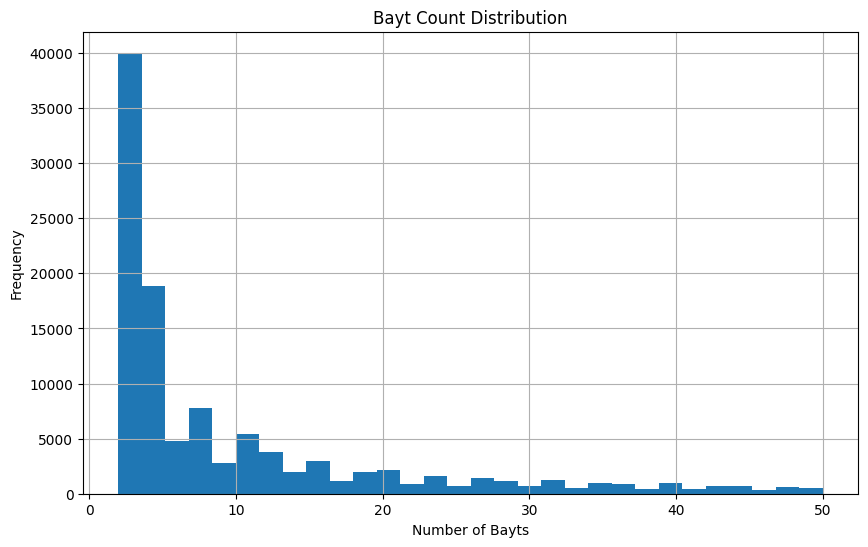

In [34]:
import matplotlib.pyplot as plt
import os

os.makedirs("img", exist_ok=True)

plt.figure(figsize=(10,6))

all_df["bayt_count"].hist(bins=30)

plt.title("Bayt Count Distribution")
plt.xlabel("Number of Bayts")
plt.ylabel("Frequency")

plt.savefig("img/bayt-count-distribution.png", dpi=300, bbox_inches="tight")

plt.show()

شو فهمنا من الرسم؟
أغلب القصائد:

تقريبًا بين:

2 → 12 أبيات

وهاد مثالي جدًا.

لكن فيه tail طويل:

في قصائد:

30
40
50 بيت
وهون القرار المهم:
هل نخليهم؟

أم نقصهم؟

بما انه الهدف:

الموديل يولد 4 أبيات ممتازة

ف رح نخلي فقط:
2 <= bayt_count <= 20

يعني:

أقل شيء: بيتين
أعلى شيء: 20 بيت
ليش؟

لأن القصائد الطويلة جدًا:

تستهلك context
تخرب GPT2 الصغير
تخلي الموديل يميل للهذيان الطويل
تقلل جودة البنية


In [35]:
all_df = all_df[
    (all_df["bayt_count"] >= 2) &
    (all_df["bayt_count"] <= 20)
]

In [36]:
print(all_df.shape)

(92533, 6)


ضل فوق:
80k

ف نحن بوضع ممتاز جدًا جدًا جدًا

بعد:

حذف الفارغ
حذف المكسور
حذف الفردي
حذف القصائد الطويلة جدًا
حذف الثيمات الضعيفة
تنظيف structure

ضل:

92,533 قصيدة نظيفة جدًا

الجودة أهم من العدد بمراحل.

وهسا :
دخلنا مرحلة التنظيف النهائي للنصوص

وهاي أهم مرحلة قبل التدريب 

بدنا نضمن:

لا رموز خربانة
لا English
لا Unicode junk
لا spacing مشاكل
لا تكرار
لا noise
لا أبيات مش شعر أصلًا

### FINAL TEXT CLEANING

In [40]:
import re

In [41]:
# تنظيف النصوص الشعرية
def clean_poem_text(text):

    text = str(text)

    # إزالة التشكيل الزائد جدًا غير المرغوب
    # (نخلي التشكيل الأساسي)
    text = re.sub(r"[ـ]+", "", text)

    # إزالة الرموز الغريبة
    text = re.sub(r"[^\u0600-\u06FF\s\|\n]+", " ", text)

    # إزالة المسافات الزائدة
    text = re.sub(r"\s+", " ", text)

    # إعادة تنسيق الأبيات
    text = text.replace(" || ", " || ")

    # تنظيف الأسطر
    lines = []

    for line in text.split("\n"):

        line = line.strip()

        if len(line) > 0:
            lines.append(line)

    text = "\n".join(lines)

    return text.strip()

In [42]:
# نطبق التنظيف
all_df["clean_poem"] = all_df["formatted_poem"].apply(
    clean_poem_text
)

In [43]:
# نفحص عينة
print(all_df["clean_poem"].iloc[0])

وَإِنّي لَأُعطي الحَقَّ مَن لَو ظَلَمتُهُ || أَقَرَّ وَأَعطاني الَّذي أَنا طالِبُ وَآخُذُ حَقّي مِن رِجالٍ أَعِزَّةٍ || وَإِن كَرُمَت أَعراقُهُم وَالمَناسِبُ


بعدها:
حذف القصائد القصيرة جدًا بالحروف

لأن أحيانًا تكون garbage.

In [44]:
all_df = all_df[
    all_df["clean_poem"].str.len() >= 80
]

In [47]:
# حذف القصائد الإنجليزية أو الغريبة

def is_arabic(text):

    arabic_chars = re.findall(r"[\u0600-\u06FF]", text)

    ratio = len(arabic_chars) / max(len(text), 1)

    return ratio > 0.7

In [48]:
all_df = all_df[
    all_df["clean_poem"].apply(is_arabic)
]

In [49]:
# حذف التكرار النهائي
all_df = all_df.drop_duplicates(
    subset=["clean_poem"]
)

In [50]:
# الحجم النهائي
print(all_df.shape)

(56011, 7)


In [51]:
# تجهيز النص النهائي للتدريب
def build_training_text(row):

    return f"""<theme> {row['theme']} </theme>

{row['clean_poem']}"""

In [52]:
all_df["training_text"] = all_df.apply(
    build_training_text,
    axis=1
)

In [53]:
# نطبق
print(all_df["training_text"].iloc[0])

<theme> قصيره </theme>

وَإِنّي لَأُعطي الحَقَّ مَن لَو ظَلَمتُهُ || أَقَرَّ وَأَعطاني الَّذي أَنا طالِبُ وَآخُذُ حَقّي مِن رِجالٍ أَعِزَّةٍ || وَإِن كَرُمَت أَعراقُهُم وَالمَناسِبُ


اكتشفنا مشكلة  مهمة :

الأسطر اختفت

صار الناتج:

بيت || بيت بيت || بيت

بدل:

بيت || بيت
بيت || بيت
السبب:

هاد السطر داخل clean_poem_text:

text = re.sub(r"\s+", " ", text)

دمّر الـ \n.

لازم نصلحه فورًا لأنه مهم جدًا لجودة الشعر.

In [54]:
def clean_poem_text(text):

    text = str(text)

    # إزالة التطويل
    text = re.sub(r"[ـ]+", "", text)

    # إزالة الرموز الغريبة مع الحفاظ على:
    # العربية + | + newline
    text = re.sub(
        r"[^\u0600-\u06FF\s\|\n]+",
        " ",
        text
    )

    # تنظيف كل سطر لحاله
    cleaned_lines = []

    for line in text.split("\n"):

        line = line.strip()

        # إزالة المسافات الزائدة داخل السطر فقط
        line = re.sub(r"\s+", " ", line)

        if line:
            cleaned_lines.append(line)

    return "\n".join(cleaned_lines)

In [55]:
all_df["clean_poem"] = all_df["formatted_poem"].apply(
    clean_poem_text
)

In [56]:
all_df["training_text"] = all_df.apply(
    build_training_text,
    axis=1
)

In [57]:
print(all_df["training_text"].iloc[0])

<theme> قصيره </theme>

وَإِنّي لَأُعطي الحَقَّ مَن لَو ظَلَمتُهُ || أَقَرَّ وَأَعطاني الَّذي أَنا طالِبُ
وَآخُذُ حَقّي مِن رِجالٍ أَعِزَّةٍ || وَإِن كَرُمَت أَعراقُهُم وَالمَناسِبُ


### EXPORT DATASET

In [58]:
# بالأعمدة المهمة
final_df = all_df[
    ["theme", "clean_poem", "training_text"]
].copy()

In [59]:
# نفحص الحجم
print(final_df.shape)

(56011, 3)


In [60]:
# export parquet
final_df.to_parquet(
    "../data/processed/final_poetry_dataset.parquet",
    index=False
)

In [61]:
# export jsonl
final_df.to_json(
    "../data/processed/final_poetry_dataset.jsonl",
    orient="records",
    force_ascii=False,
    lines=True
)

In [62]:
final_df.to_excel(
    "../data/processed/final_poetry_dataset.xlsx",
    index=False
)

اخر خطوة نعمل 
train/validation split

الشغل موجود ب  training_split.ipynb
وهيك :

خلصنا data pipeline كاملة
